# Ocular dominance across the visual field

Is the fellow-eye dominance of the amblyopes the same everywhere in the visual field, or stronger in the centre (where the amblyopic deficit and the suppression are strongest)? As de Hollander et al. (2021), every vertex is placed in the visual field at the position of its pRF; here the OD measures of Figures 1-2 (`od_final_figures_v5.ipynb`) are computed per eccentricity band and per part of the visual field.

- **pRF position of a vertex** = mean of the pRF x / y of the two eyes (symmetric in the two eyes, so the same in the three versions of sub-05).
- **Eccentricity bands**: `ecc_th[0]`–2°, 2–4°, 4°–`ecc_th[1]`. **Visual field**: upper vs lower (pRF y > 0 / < 0), horizontal vs vertical meridian (polar angle within 45° of the horizontal or of the vertical).
- **Measures** (per subject × ROI × band, vertices of Figures 1-2, weight = mean pRF R², ≥ 10 vertices): weighted % of vertices preferring FE-LE, weighted median of the vertex OD index.
- **Tests** (amblyopes): each band vs H0 (Wilcoxon one-sided, FE > AE); centre vs periphery (paired Wilcoxon, two-sided, band 1 vs band 3); amblyopes vs controls on the centre − periphery difference (Mann-Whitney). FDR over the 8 ROIs. Controls: each band vs H0 (two-sided).
- **Visual-field maps**: per subject, weighted % FE in 1° × 1° cells of the visual field, then median across subjects (cells with ≥ 4 subjects).

Every result is shown for the three versions of sub-05 (as labelled, swapped, excluded). Data: same caches as `od_final_figures_v5.ipynb`. Figures in `Desktop/fig_od` (`od_vf_*`).

In [3]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats, integrate
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from plot_utils import plotly_template

# Project plotting functions (amblyo7T_prf/utils/plot_utils.py, same module name as analysis_code/utils/plot_utils.py)
import importlib.util
spec = importlib.util.spec_from_file_location('project_plot_utils', '{}/../utils/plot_utils.py'.format(os.getcwd()))
project_plot_utils = importlib.util.module_from_spec(spec)
spec.loader.exec_module(project_plot_utils)

In [4]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'       # per-run GLM sums (od_glm_common_analysis.ipynb)
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
subjects = patients + controls                 # analysed subjects = the two groups (not analysis_info['subjects'])
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis
task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

# prf_analysis filters (applied to both eyes)
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye of each patient
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Eye scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)
# sub-05: eye labels uncertain (see od_prf_sub05_versions.ipynb), every figure is made for the 3 versions
target = 'sub-05'
versions = ['as labelled', 'swapped', 'excluded']
version_suffix = {'as labelled': 'sub05-as-labelled', 'swapped': 'sub05-swapped', 'excluded': 'sub05-excluded'}

# Figure 4: subject TSVs of make_ecc_size_pcm_tsv.py (new fits)
output_folder = 'prfmodel'


In [5]:
def bh_fdr(p):
    """Benjamini-Hochberg FDR correction."""
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


def wcorr(x, y, w):
    """Weighted rank correlation: Pearson correlation of the ranks of x and y, each vertex weighted by w."""
    x, y, w = stats.rankdata(x), stats.rankdata(y), np.asarray(w, float)
    if np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def bf10_ttest(x, h0=0, r=np.sqrt(2) / 2):
    """JZS Bayes factor BF10 of a one-sample t-test (Rouder et al. 2009), Cauchy prior of scale r on the effect size."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - h0
    n, v = x.size, x.size - 1
    t = x.mean() / (x.std(ddof=1) / np.sqrt(n))
    null = (1 + t ** 2 / v) ** (-(v + 1) / 2)
    alt = integrate.quad(lambda g: (1 + n * g * r ** 2) ** -0.5
                         * (1 + t ** 2 / ((1 + n * g * r ** 2) * v)) ** (-(v + 1) / 2)
                         * (2 * np.pi) ** -0.5 * g ** -1.5 * np.exp(-1 / (2 * g)), 0, np.inf)[0]
    return alt / null


def within_tests(df, value, h0, alt_patient='greater', alt_control='two-sided'):
    """Per ROI: Wilcoxon of each group vs h0 (FDR over the ROIs) + Bayes factor BF01 of the controls."""
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        rows.append({'roi': roi, 'median_patients': vp.median(), 'median_controls': vc.median(),
                     'p_patients': stats.wilcoxon(vp - h0, alternative=alt_patient).pvalue,
                     'p_controls': stats.wilcoxon(vc - h0, alternative=alt_control).pvalue,
                     'BF01_controls': 1 / bf10_ttest(vc, h0)})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_patients_fdr'] = bh_fdr(s.p_patients)
    s['p_controls_fdr'] = bh_fdr(s.p_controls)
    return s


# Figure settings (as the other pRF figures)
template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)", font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
groups = ['patient', 'control']
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
cols = len(rois_to_keep)
fig_height = rois_plot_height * 2 + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])


def bar_figure(df, values, s, y_title, y_ticks, tick_fmt, fn_out, legends=None, patterns=None, ref=None):
    """Median and 25-75 percentiles per group and ROI + one dot per subject (as Figure 3);
    stars = within-group test of s (FDR); ref = reference line (H0)."""
    patterns = patterns or [''] * len(values)
    rng_dots = np.random.default_rng(0)                                   # same jitter at each run
    w = 0.7 / len(values)
    offs = (np.arange(len(values)) - (len(values) - 1) / 2) * w
    y_step = (y_ticks[-1] - y_ticks[0]) * 0.05
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = df[df.roi == roi]
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        if ref is not None:
            fig.add_shape(type='line', x0=0, x1=1, y0=ref, y1=ref, xref='{} domain'.format(xref), yref=yref,
                          line=dict(color='grey', width=1))
        for g_i, group in enumerate(groups):
            color = roi_colors_rgb[roi] if group == 'patient' else ctrl_color
            top = 0
            for value, pattern, off in zip(values, patterns, offs):
                dv = d[d.group == group].dropna(subset=[value])
                v = dv[value]
                is_target = (dv.subject == target).values                       # sub-05 in red
                med, p25, p75 = v.median(), np.percentile(v, 25), np.percentile(v, 75)
                fig.add_trace(go.Bar(x=[g_i + off], y=[med], width=w * 0.9, showlegend=False,
                                     marker=dict(color=color, pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                                           bgcolor='rgba(0,0,0,0)', size=8)),
                                     error_y=dict(type='data', array=[p75 - med], arrayminus=[med - p25], visible=True,
                                                  thickness=2, width=0, color='rgba(0,0,0,1)')),
                              row=1, col=col_idx)
                fig.add_trace(go.Scatter(x=g_i + off + rng_dots.uniform(-w * 0.2, w * 0.2, len(v)), y=v, mode='markers',
                                         showlegend=False,
                                         marker=dict(size=np.where(is_target, 9, 5),
                                                     color=np.where(is_target, 'rgba(255,0,0,1)', 'rgba(0,0,0,0.6)'))),
                              row=1, col=col_idx)
                top = max(top, v.max())
            p = s.loc[roi, 'p_{}_fdr'.format('patients' if group == 'patient' else 'controls')]
            fig.add_annotation(x=g_i, y=min(top + y_step / 2, y_ticks[-1] + y_step), xref=xref, yref=yref, text=stars(p),
                               showarrow=False, font=dict(size=16, color='black'), yanchor='bottom')
        fig.add_shape(type='line', x0=0, x1=0, y0=y_ticks[0], y1=y_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                      line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
    if legends:
        for legend, pattern in zip(legends, patterns):
            fig.add_trace(go.Bar(x=[None], y=[None], name=legend,
                                 marker=dict(color='rgba(128,128,128,1)',
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0.3)', size=8)),
                                 showlegend=True), row=1, col=1)
    fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0, range=[-0.6, 1.6],
                     tickvals=[0, 1], ticktext=[group_labels[g] for g in groups])
    fig.update_yaxes(showline=False, range=[y_ticks[0], y_ticks[-1] + 3 * y_step], tickvals=y_ticks,
                     ticktext=[tick_fmt.format(t) for t in y_ticks], showticklabels=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(height=fig_height, width=fig_width, template=fig_template,
                      legend=dict(orientation='h', font_family=template_specs['font'],
                                  font_size=template_specs['axes_font_size'], x=1, y=1.15, xanchor='right',
                                  yanchor='bottom', bgcolor='rgba(0,0,0,0)', traceorder='normal', itemwidth=30),
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


def nice_ticks(values, step):
    lo = min(0, np.floor(np.nanmin(values) / step) * step)
    hi = max(step, np.ceil(np.nanmax(values) / step) * step)
    return np.round(np.arange(lo, hi + step / 2, step), 3)


def wpearson(x, y, w):
    """Weighted Pearson correlation (= correlation of a weighted linear regression)."""
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if np.sum(w) == 0 or len(x) < 3:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def deming(x, y, w=None):
    """Weighted Deming (orthogonal) regression, as in make_corr_tsv.py: returns slope, intercept.
    Symmetric in x and y (both halves are measured with noise), weights normalised to sum 1."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w)
    x, y, w = x[ok], y[ok], w[ok]
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan, np.nan
    w = w / np.sum(w)
    mx, my = np.sum(w * x), np.sum(w * y)
    sxx, syy, sxy = np.sum(w * (x - mx) ** 2), np.sum(w * (y - my) ** 2), np.sum(w * (x - mx) * (y - my))
    if sxy == 0:
        return np.nan, np.nan
    slope = (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)
    return slope, my - slope * mx


def wmedian(x, w):
    """Weighted median: first value where the cumulative weight reaches half of the total."""
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok])
    cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def od_index(b_fe, b_ae):
    """OD index (FE - AE) / (FE + AE); defined for positive betas only."""
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)

## Data (as od_final_figures_v5.ipynb)

In [7]:
# ---------- local cache of the vertex data (vertices of the 8 ROIs only)
vcache_dir = '{}/od_vertex_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)
deriv_keys = ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude', 'prf_x', 'prf_y']


def subject_files(subject):
    fns = [file_spec.format(pp_dir, subject, subject, task, '', hemi, 'od') for hemi in ['L', 'R']]
    for eye in eyes.values():
        for kind in ['deriv', 'stats']:
            fns += [file_spec.format(pp_dir, subject, subject, task, eye, hemi, kind) for hemi in ['L', 'R']]
    return fns


def load_subject(subject):
    """Vertex data of one subject: betas, pRF parameters and fit p-value of each eye, ROI masks (full-length arrays).
    Read from the local cache when it is newer than all the source files, otherwise from the data disks (then cached)."""
    fns = subject_files(subject)
    if not all(os.path.isfile(fn) for fn in fns):
        return None
    cache_fn = '{}/{}_od-vertex-cache.npz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(fn) for fn in fns)
    if not (os.path.isfile(cache_fn) and float(np.load(cache_fn)['src_mtime']) >= src_mtime):
        od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
        rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
        idx = np.where(np.any([rois[roi] for roi in rois_to_keep], axis=0))[0]
        save = {'n_vertices': od_mat.shape[1], 'idx': idx, 'src_mtime': src_mtime,
                'beta_L': od_mat[maps_names_css_od.index('od_beta_le')][idx].astype(np.float32),
                'beta_R': od_mat[maps_names_css_od.index('od_beta_re')][idx].astype(np.float32)}
        for roi in rois_to_keep:
            save['roi_{}'.format(roi)] = rois[roi][idx]
        for e, eye in eyes.items():
            deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                          R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
            st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'stats'),
                                       R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'stats'))['data_concat']
            for key in deriv_keys:
                save['{}_{}'.format(e, key)] = deriv[maps_names_css.index(key)][idx].astype(np.float32)
            save['{}_p'.format(e)] = st[maps_names_css_stats.index(p_name)][idx].astype(np.float32)
        np.savez_compressed(cache_fn, **save)
        print('{}: read from the data disks, cached'.format(subject), end=' | ')
    c = np.load(cache_fn)
    n, idx = int(c['n_vertices']), c['idx']

    def full(x, fill=np.nan):
        out = np.full(n, fill, dtype=float if fill is not False else bool)
        out[idx] = x
        return out
    return {'beta': {e: full(c['beta_{}'.format(e)]) for e in eyes},
            'd': {e: {key: full(c['{}_{}'.format(e, key)]) for key in deriv_keys} for e in eyes},
            'p': {e: full(c['{}_p'.format(e)]) for e in eyes},
            'rois': {roi: full(c['roi_{}'.format(roi)], False) for roi in rois_to_keep}}


def select(d, p):
    """prf_analysis filters of one eye + positive pRF amplitude (p = p-value of the pRF fit)."""
    with np.errstate(invalid='ignore'):
        return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
                & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
                & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
                & (d['prf_rsq'] >= rsqr_th)
                & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
                & (p <= stats_th))


def pref_percent(b_a, b_b, w):
    return 100 * np.sum(w * (b_a > b_b)) / np.sum(w) if np.sum(w) > 0 else np.nan


rows, vertex_data = [], {}
for subject, swap in [(s, False) for s in subjects] + [(target, True)]:
    group = 'patient' if subject in patients else 'control' if subject in controls else None
    sd = load_subject(subject)
    if sd is None:
        print('{}: OD image or pRF files missing, skipped'.format(subject))
        continue
    beta = sd['beta']
    if swap:
        beta = {'L': beta['R'], 'R': beta['L']}
    keep_eye = {e: select(sd['d'][e], sd['p'][e]) & np.isfinite(beta[e]) for e in eyes}
    rsq_eye = {e: sd['d'][e]['prf_rsq'] for e in eyes}
    weight = np.nan_to_num(np.clip(np.nanmean([rsq_eye['L'], rsq_eye['R']], axis=0), 0, None))   # mean pRF R² of both eyes

    # FE-LE / AE-RE: amblyopes -> fellow / amblyopic eye, controls -> left / right eye
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    b_fe, b_ae = beta[fe], beta[ae]
    keep = keep_eye['L'] & keep_eye['R']                            # pRF filters on both eyes, all betas kept
    vertex_data[subject] = {'fe': fe, 'keep': keep, 'w': weight}

    rois = sd['rois']
    for roi in rois_to_keep:
        mask = rois[roi] & keep
        w = weight[mask]
        if mask.sum() < 10 or np.sum(w) == 0:
            continue
        mask_fe, mask_ae = rois[roi] & keep_eye[fe], rois[roi] & keep_eye[ae]
        rows.append({'subject': subject, 'swapped': swap, 'group': group, 'roi': roi, 'n_vertices': mask.sum(),
                     'fe_le_first': first_eye[subject] == fe,
                     # vertices with beta <= 0 (kept in Figure 1, excluded from the vertex OD index)
                     'neg_any_pct': 100 * np.mean((b_fe[mask] <= 0) | (b_ae[mask] <= 0)),
                     'neg_any_w_pct': 100 * np.sum(w * ((b_fe[mask] <= 0) | (b_ae[mask] <= 0))) / np.sum(w),
                     'neg_fe_only_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] > 0)),
                     'neg_ae_only_pct': 100 * np.mean((b_ae[mask] <= 0) & (b_fe[mask] > 0)),
                     'neg_both_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] <= 0)),
                     # measures
                     'pref_FE-LE': pref_percent(b_fe[mask], b_ae[mask], w),
                     'pref_AE-RE': pref_percent(b_ae[mask], b_fe[mask], w),
                     'od_index': wmedian(od_index(b_fe[mask], b_ae[mask]), w),     # weighted median of the vertex OD index (both β > 0)
                     # vertex-selection checks
                     'pref_fe_sel': pref_percent(b_fe[mask_fe], b_ae[mask_fe], weight[mask_fe]),
                     'pref_ae_sel': pref_percent(b_fe[mask_ae], b_ae[mask_ae], weight[mask_ae]),
                     'rsq_fe': np.nanmedian(rsq_eye[fe][mask]), 'rsq_ae': np.nanmedian(rsq_eye[ae][mask])})
    print('{}{}: done'.format(subject, ' (swapped)' if swap else ''))
df_subjects = pd.DataFrame(rows)
df_subjects.groupby(['group', 'roi'])[['n_vertices', 'pref_FE-LE', 'od_index']].median().unstack('group').reindex(rois_to_keep).round(3)

# The three versions of the subject table
others = df_subjects[(~df_subjects.swapped) & (df_subjects.subject != target)]
dfs = {'as labelled': df_subjects[~df_subjects.swapped],
       'swapped': pd.concat([others, df_subjects[df_subjects.swapped]], ignore_index=True),
       'excluded': others}
for v in versions:
    print('{}: {} amblyopes, {} controls'.format(v, dfs[v][dfs[v].group == 'patient'].subject.nunique(),
                                                  dfs[v][dfs[v].group == 'control'].subject.nunique()))

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done
sub-05 (swapped): done
as labelled: 11 amblyopes, 8 controls
swapped: 11 amblyopes, 8 controls
excluded: 10 amblyopes, 8 controls


## Measures per eccentricity band and per part of the visual field

In [10]:
import matplotlib.pyplot as plt

ecc_edges = [ecc_th[0], 2, 4, ecc_th[1]]
ecc_labels = ['{:g}-{:g}°'.format(a, b) for a, b in zip(ecc_edges[:-1], ecc_edges[1:])]
min_vert = 10


def subject_vertices(subject, swap):
    """Vertex table (selected vertices of the 8 ROIs) with pRF position, weight, betas FE / AE."""
    sd = load_subject(subject)
    beta = sd['beta']
    if swap:
        beta = {'L': beta['R'], 'R': beta['L']}
    keep_eye = {e: select(sd['d'][e], sd['p'][e]) & np.isfinite(beta[e]) for e in eyes}
    keep = keep_eye['L'] & keep_eye['R']
    w = np.nan_to_num(np.clip(np.nanmean([sd['d']['L']['prf_rsq'], sd['d']['R']['prf_rsq']], axis=0), 0, None))
    x = np.nanmean([sd['d']['L']['prf_x'], sd['d']['R']['prf_x']], axis=0)
    y = np.nanmean([sd['d']['L']['prf_y'], sd['d']['R']['prf_y']], axis=0)
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    roi_lab = np.full(len(w), '', dtype=object)
    for roi in rois_to_keep:
        roi_lab[sd['rois'][roi]] = roi
    m = keep & (roi_lab != '') & (w > 0)
    d = pd.DataFrame({'roi': roi_lab[m], 'x': x[m], 'y': y[m], 'w': w[m], 'b_fe': beta[fe][m], 'b_ae': beta[ae][m]})
    d['ecc'] = np.hypot(d.x, d.y)
    d['ecc_band'] = pd.cut(d.ecc, ecc_edges, labels=ecc_labels, include_lowest=True)
    d['field'] = np.where(d.y >= 0, 'upper', 'lower')
    ang = np.degrees(np.arctan2(np.abs(d.y), np.abs(d.x)))
    d['meridian'] = np.where(ang < 45, 'horizontal', 'vertical')
    d['od'] = od_index(d.b_fe.values, d.b_ae.values)
    return d


def band_rows(subject, group, d, col):
    rows = []
    for (roi, band), g in d.groupby(['roi', col], observed=True):
        if len(g) < min_vert:
            continue
        rows.append({'subject': subject, 'group': group, 'roi': roi, col: band, 'n_vertices': len(g),
                     'pref_FE-LE': pref_percent(g.b_fe.values, g.b_ae.values, g.w.values),
                     'od_index': wmedian(g.od.values, g.w.values)})
    return rows


vtx, rows = {}, {c: [] for c in ['ecc_band', 'field', 'meridian']}
for subject, swap in [(s, False) for s in patients + controls] + [(target, True)]:
    if load_subject(subject) is None:
        continue
    group = 'patient' if subject in patients else 'control'
    d = subject_vertices(subject, swap)
    vtx[(subject, swap)] = d
    for col in rows:
        for r in band_rows(subject, group, d, col):
            r['swapped'] = swap
            rows[col].append(r)
tabs = {col: pd.DataFrame(r) for col, r in rows.items()}


def version(df, v):
    """Subject table of one version of sub-05."""
    if v == 'as labelled':
        return df[~df.swapped]
    if v == 'swapped':
        return df[(~df.swapped & (df.subject != target)) | df.swapped]
    return df[~df.swapped & (df.subject != target)]

print(tabs['ecc_band'][~tabs['ecc_band'].swapped].groupby(['group', 'ecc_band'], observed=True).n_vertices.median().unstack())

ecc_band  0.05-2°   2-4°  4-20°
group                          
control     819.0  514.0  633.0
patient     588.0  557.5  644.0


## Statistics per eccentricity band

For each measure and version: median of the amblyopes per ROI and band (p FDR vs H0, one-sided), centre vs periphery in the amblyopes (paired Wilcoxon), and amblyopes vs controls on the centre − periphery difference. Controls: median per band (p FDR vs H0, two-sided).

In [12]:
def wil(x, alt='two-sided'):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return stats.wilcoxon(x, alternative=alt).pvalue if len(x) > 2 and np.any(x != 0) else np.nan


def mwu(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    return stats.mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan


def fdr(p):
    p = np.asarray(p, float)
    out = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    if ok.any():
        out[ok] = bh_fdr(p[ok])
    return out


def ecc_stats(df, meas, h0):
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        row = {'roi': roi}
        piv = {g: d[d.group == g].pivot(index='subject', columns='ecc_band', values=meas).reindex(columns=ecc_labels)
               for g in ['patient', 'control']}
        for b in ecc_labels:
            row['A ' + b] = piv['patient'][b].median()
            row['p A ' + b] = wil(piv['patient'][b] - h0, 'greater')
            row['C ' + b] = piv['control'][b].median()
            row['p C ' + b] = wil(piv['control'][b] - h0)
        diff_p = piv['patient'][ecc_labels[0]] - piv['patient'][ecc_labels[-1]]
        diff_c = piv['control'][ecc_labels[0]] - piv['control'][ecc_labels[-1]]
        row['A centre-periph'] = diff_p.median()
        row['p A centre vs periph'] = wil(diff_p)
        row['p centre-periph A vs C'] = mwu(diff_p, diff_c)
        rows.append(row)
    s = pd.DataFrame(rows).set_index('roi')
    for col in [c for c in s.columns if c.startswith('p ')]:
        s[col] = fdr(s[col])
    return s

h0s = {'pref_FE-LE': 50, 'od_index': 0}
ecc_res = {(m, v): ecc_stats(version(tabs['ecc_band'], v), m, h0) for m, h0 in h0s.items() for v in versions}
for m in h0s:
    for v in versions:
        print('\n=== {} — sub-05 {} (p = FDR over ROIs) ==='.format(m, v))
        print(ecc_res[(m, v)].round(3).to_string())


=== pref_FE-LE — sub-05 as labelled (p = FDR over ROIs) ===
     A 0.05-2°  p A 0.05-2°  C 0.05-2°  p C 0.05-2°  A 2-4°  p A 2-4°  C 2-4°  p C 2-4°  A 4-20°  p A 4-20°  C 4-20°  p C 4-20°  A centre-periph  p A centre vs periph  p centre-periph A vs C
roi                                                                                                                                                                                           
V1      60.597        0.120     47.543          1.0  60.621     0.137  50.802      1.00   63.294      0.068   57.438      0.922            1.392                 0.831                   0.960
V2      67.143        0.054     61.663          1.0  70.397     0.068  55.628      1.00   59.113      0.054   48.778      0.945           -2.660                 0.729                   0.960
V3      70.459        0.054     53.707          1.0  77.342     0.054  47.751      1.00   58.222      0.054   51.946      0.945            7.336                 0.557         

## Figure VF1 — OD per eccentricity band

Median across subjects (error bars 25-75 %) per ROI and band; amblyopes in ROI colour, controls in grey; dots = subjects, sub-05 in red. Stars above a band: amblyopes vs H0 (FDR); text: centre vs periphery p (FDR).

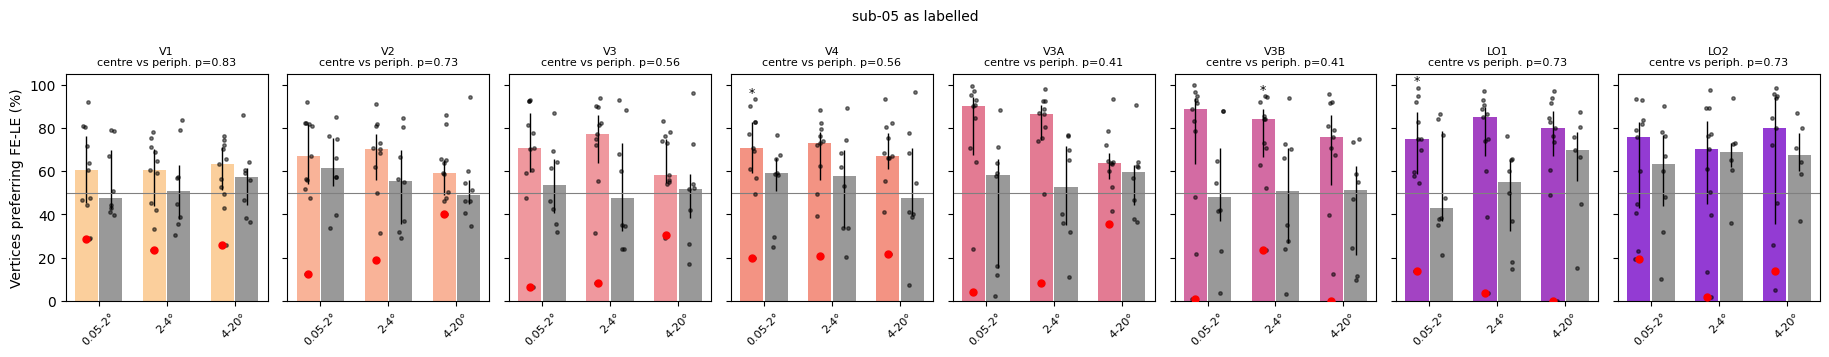

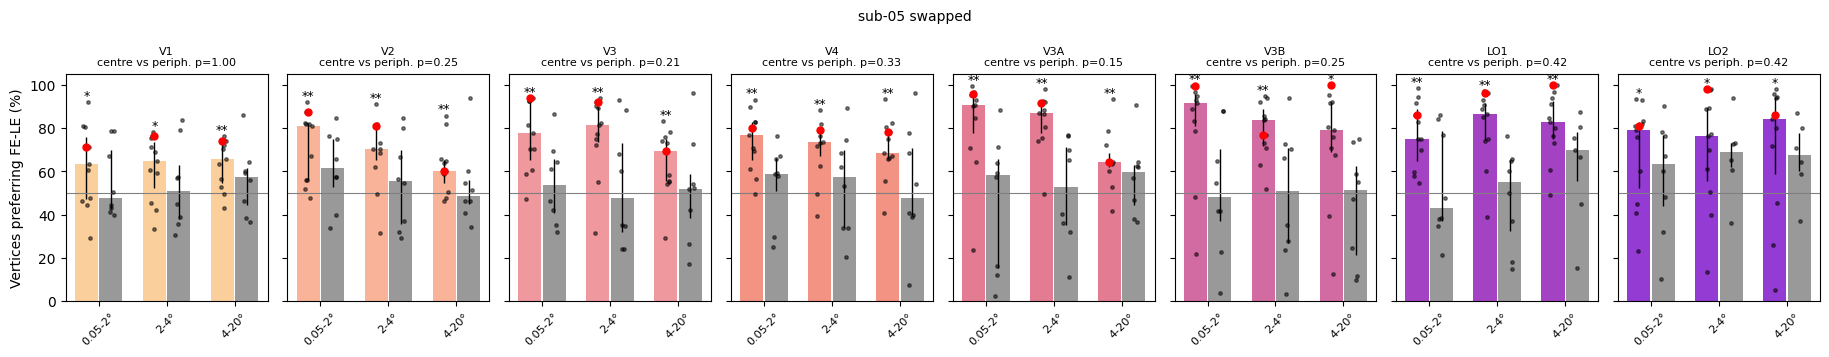

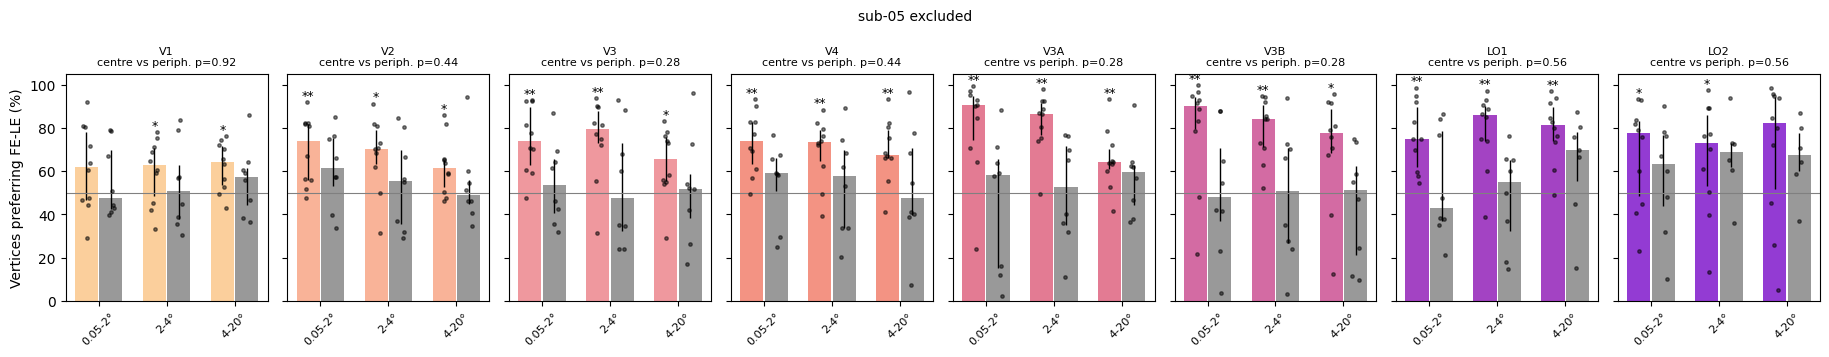

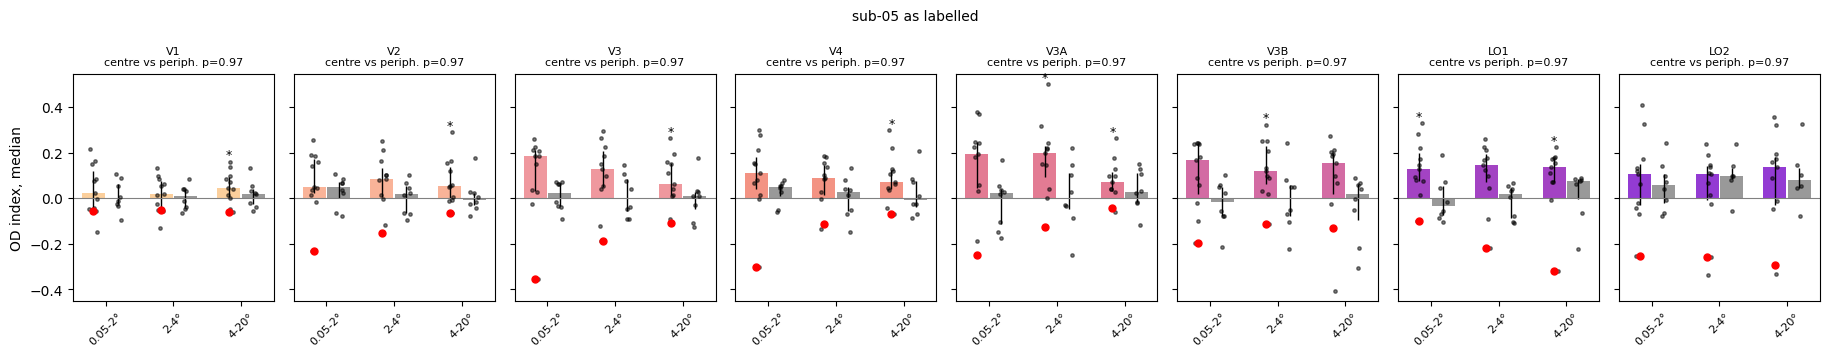

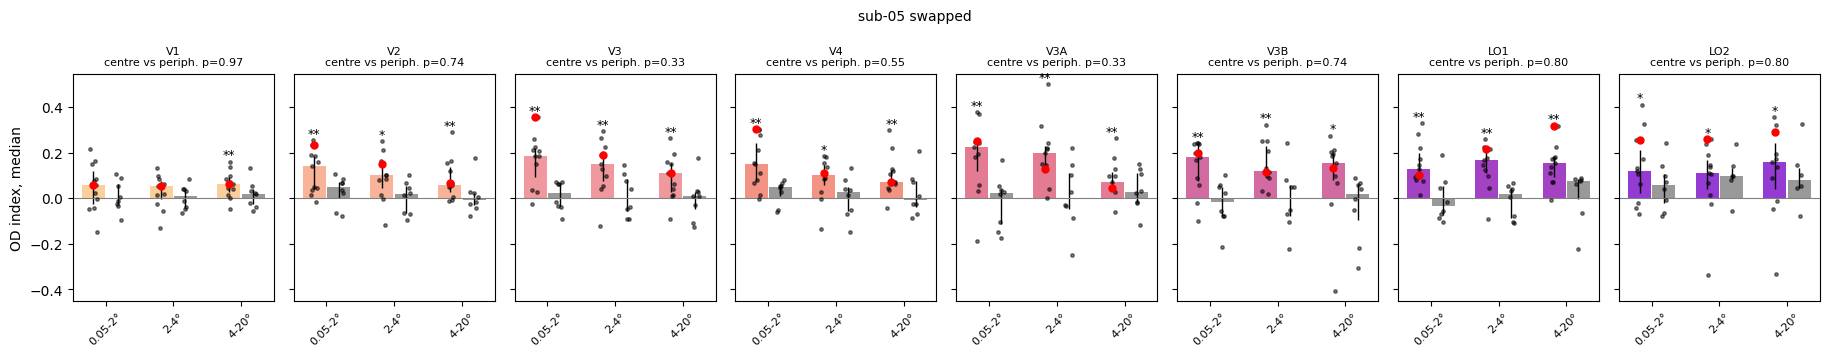

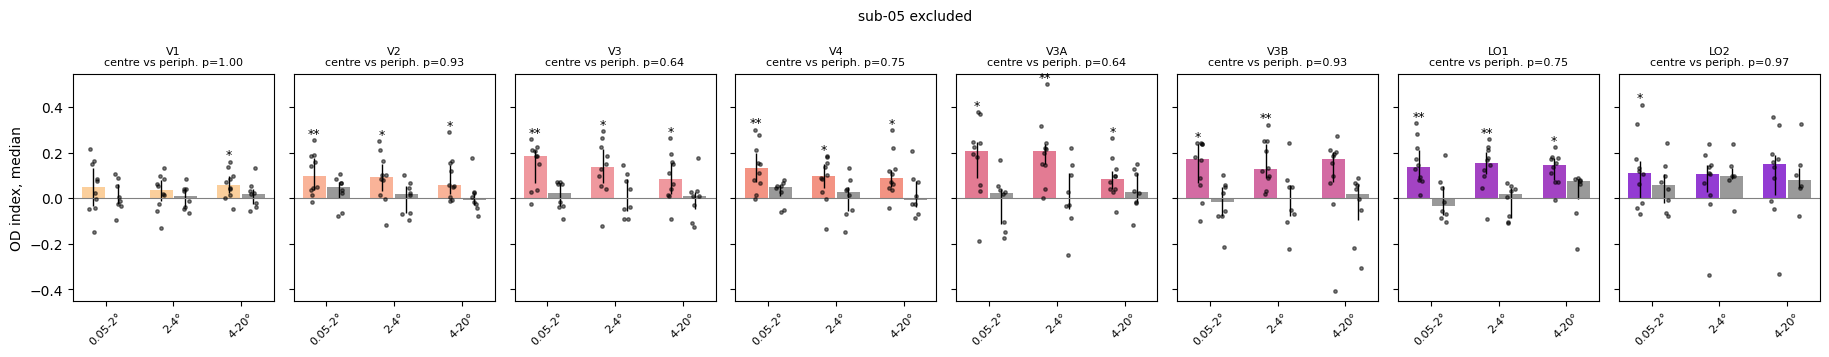

In [16]:
def ecc_figure(meas, v, ylab, h0, fn):
    df = version(tabs['ecc_band'], v)
    s = ecc_res[(meas, v)]
    fig, axes = plt.subplots(1, len(rois_to_keep), figsize=(2.3 * len(rois_to_keep), 3.6), sharey=True)
    xs = np.arange(len(ecc_labels))
    rng = np.random.default_rng(0)
    for ax, roi in zip(axes, rois_to_keep):
        d = df[df.roi == roi]
        col = np.array(roi_colors_rgb[roi].replace('rgb(', '').replace(')', '').split(','), float) / 255 \
            if roi_colors_rgb[roi].startswith('rgb') else roi_colors_rgb[roi]
        for g, off, c in [('patient', -0.18, col), ('control', 0.18, 'grey')]:
            piv = d[d.group == g].pivot(index='subject', columns='ecc_band', values=meas).reindex(columns=ecc_labels)
            med, q1, q3 = piv.median(), piv.quantile(0.25), piv.quantile(0.75)
            ax.bar(xs + off, med, 0.34, color=c, alpha=0.8)
            ax.errorbar(xs + off, med, yerr=[med - q1, q3 - med], fmt='none', ecolor='k', lw=1)
            for k, b in enumerate(ecc_labels):
                vals = piv[b]
                ax.scatter(xs[k] + off + rng.uniform(-0.06, 0.06, len(vals)), vals, s=6, c='k', alpha=0.5, zorder=3)
                if target in piv.index:
                    ax.scatter(xs[k] + off, piv.loc[target, b], s=25, c='red', zorder=4)
                if g == 'patient':
                    p = s.loc[roi, 'p A ' + b]
                    if np.isfinite(p) and p < 0.05:
                        ax.text(xs[k] + off, np.nanmax(vals), stars(p), ha='center', va='bottom', fontsize=9)
        ax.axhline(h0, color='grey', lw=0.8)
        ax.set_xticks(xs)
        ax.set_xticklabels(ecc_labels, rotation=45, fontsize=8)
        ax.set_title('{}\ncentre vs periph. p={:.2f}'.format(roi, s.loc[roi, 'p A centre vs periph']), fontsize=8)
    axes[0].set_ylabel(ylab)
    fig.suptitle('sub-05 {}'.format(v), fontsize=10)
    plt.tight_layout()
    fig.savefig('{}/{}_{}.pdf'.format(fig_dir, fn, version_suffix[v]), bbox_inches='tight')
    plt.show()


for v in versions:
    ecc_figure('pref_FE-LE', v, 'Vertices preferring FE-LE (%)', 50, 'od_vf1_pref_ecc')
for v in versions:
    ecc_figure('od_index', v, 'OD index, median', 0, 'od_vf1_odindex_ecc')

## Upper vs lower field, horizontal vs vertical meridian

Amblyopes: median % of vertices preferring FE in each half, and paired Wilcoxon between the two halves (two-sided, FDR over the ROIs).

In [18]:
def half_stats(col, a, b, meas='pref_FE-LE'):
    out = {}
    for v in versions:
        df = version(tabs[col], v)
        df = df[df.group == 'patient']
        rows = []
        for roi in rois_to_keep:
            piv = df[df.roi == roi].pivot(index='subject', columns=col, values=meas)
            rows.append({'roi': roi, a: piv[a].median(), b: piv[b].median(), 'p': wil(piv[a] - piv[b])})
        s = pd.DataFrame(rows).set_index('roi')
        s['p_fdr'] = fdr(s.p)
        out[v] = s[[a, b, 'p_fdr']]
    return pd.concat(out, axis=1).round(3)

print('Upper vs lower visual field (% FE, amblyopes)')
print(half_stats('field', 'upper', 'lower').to_string())
print('\nHorizontal vs vertical meridian (% FE, amblyopes)')
print(half_stats('meridian', 'horizontal', 'vertical').to_string())

Upper vs lower visual field (% FE, amblyopes)
    as labelled                swapped                excluded               
          upper   lower  p_fdr   upper   lower  p_fdr    upper   lower  p_fdr
roi                                                                          
V1       55.925  63.391  0.898  61.302  64.234  1.000   58.614  63.812  0.922
V2       71.142  57.263  0.898  71.341  68.706  0.824   71.242  63.239  0.922
V3       66.129  74.157  0.898  69.814  75.177  1.000   67.971  74.667  0.922
V4       67.995  69.098  0.898  70.958  74.382  1.000   69.476  71.740  0.922
V3A      74.730  66.508  0.539  77.620  68.780  0.195   76.175  67.644  0.297
V3B      82.239  77.929  0.898  84.911  77.929  0.974   83.575  78.670  0.922
LO1      79.395  76.984  0.898  82.764  79.220  1.000   82.040  78.102  0.922
LO2      65.967  73.193  0.898  80.183  76.118  1.000   75.938  74.655  0.922

Horizontal vs vertical meridian (% FE, amblyopes)
    as labelled                    swapped   

## Figure VF2 — maps of the visual field

Per subject, weighted % of vertices preferring FE-LE in 1° × 1° cells (≥ 5 vertices per cell), then median across subjects (cells with ≥ 4 subjects). Amblyopes (three versions of sub-05) and controls; V1, V2-V3 and V4 to LO2 pooled. Red = fellow eye (or left eye for the controls), blue = amblyopic eye (right eye).

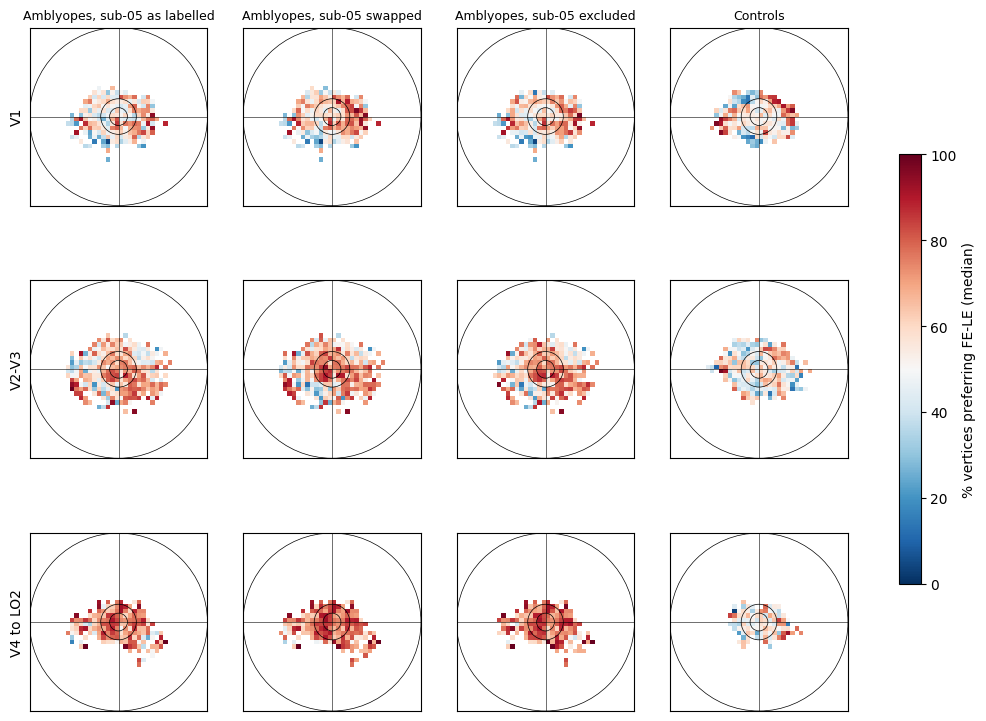

In [21]:
cell = 1.0
grid = np.arange(-ecc_th[1], ecc_th[1] + cell, cell)
roi_sets = {'V1': ['V1'], 'V2-V3': ['V2', 'V3'], 'V4 to LO2': ['V4', 'V3A', 'V3B', 'LO1', 'LO2']}


def subject_map(d, roi_set):
    d = d[d.roi.isin(roi_set)]
    ix = np.digitize(d.x, grid) - 1
    iy = np.digitize(d.y, grid) - 1
    n = len(grid) - 1
    num, den, cnt = np.zeros((n, n)), np.zeros((n, n)), np.zeros((n, n))
    ok = (ix >= 0) & (ix < n) & (iy >= 0) & (iy < n)
    np.add.at(num, (iy[ok], ix[ok]), (d.w.values * (d.b_fe.values > d.b_ae.values))[ok])
    np.add.at(den, (iy[ok], ix[ok]), d.w.values[ok])
    np.add.at(cnt, (iy[ok], ix[ok]), 1)
    with np.errstate(invalid='ignore', divide='ignore'):
        m = 100 * num / den
    m[cnt < 5] = np.nan
    return m


def group_map(keys, roi_set):
    maps = np.array([subject_map(vtx[k], roi_set) for k in keys])
    n_ok = np.sum(np.isfinite(maps), axis=0)
    med = np.nanmedian(maps, axis=0)
    med[n_ok < 4] = np.nan
    return med

pat_keys = {'as labelled': [(s, False) for s in patients if (s, False) in vtx],
            'swapped': [(s, False) for s in patients if (s, False) in vtx and s != target] + [(target, True)],
            'excluded': [(s, False) for s in patients if (s, False) in vtx and s != target]}
ctrl_keys = [(s, False) for s in controls if (s, False) in vtx]
panels = [('Amblyopes, sub-05 ' + v, pat_keys[v]) for v in versions] + [('Controls', ctrl_keys)]

fig, axes = plt.subplots(len(roi_sets), len(panels), figsize=(3.3 * len(panels), 3.1 * len(roi_sets)))
for r, (set_name, roi_set) in enumerate(roi_sets.items()):
    for c, (title, keys) in enumerate(panels):
        ax = axes[r, c]
        im = ax.imshow(group_map(keys, roi_set), origin='lower', cmap='RdBu_r', vmin=0, vmax=100,
                       extent=[grid[0], grid[-1], grid[0], grid[-1]])
        for rad in ecc_edges[1:]:
            ax.add_patch(plt.Circle((0, 0), rad, fill=False, lw=0.5, color='k'))
        ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(title, fontsize=9)
        if c == 0:
            ax.set_ylabel(set_name)
fig.colorbar(im, ax=axes, shrink=0.6, label='% vertices preferring FE-LE (median)')
fig.savefig('{}/od_vf2_maps.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## Reading guide

- **Centre > periphery in the amblyopes** (and not in the controls): the fellow-eye dominance is strongest where the amblyopic deficit is (central vision), consistent with central suppression in strabismic amblyopia.
- **No difference**: the dominance is uniform across the stimulated field (up to `ecc_th[1]`°).
- The visual field is limited to the stimulated region; the blind spot (~15°) used by de Hollander et al. is outside it.
- Bands and cells are small: the per-band tests have less power than those of Figures 1-2, and the maps are descriptive.